# ISL Static Sign Recognition with MediaPipe Landmarks

This notebook converts your `Indian/` image-folder dataset into MediaPipe hand-landmark features, trains a classifier, evaluates it, and saves the model.

**Your ZIP was inspected:** 42,745 images across 35 classes (A–Z and 1–9), with images at 128×128 pixels.

> Scope: this dataset appears to contain static images. This notebook recognizes static signs, not continuous sign-language sentences or movement-based signs. Some signs use two hands, so the extractor keeps landmarks for up to two hands.

## Important evaluation note
If multiple images are near-identical frames from the same recording/person, a random split can overestimate real-world accuracy. For a reliable project evaluation, split by signer/session if that information is available. The stratified split below is a first baseline, not a guarantee of signer-independent performance.


## 1. Install dependencies

Run this cell in Google Colab or a local Jupyter notebook.

In [1]:
%pip install -q mediapipe opencv-python pandas numpy scikit-learn joblib matplotlib

Note: you may need to restart the kernel to use updated packages.


## 2. Set the dataset path and extract the ZIP

### Google Colab
Upload `ISL dataset.zip` to the Colab session, or mount Google Drive and set `ZIP_PATH` to its Drive path.

### Local Jupyter on Windows
Set `ZIP_PATH` to the full path of your ZIP, for example `r"C:\\Users\\YourName\\Downloads\\ISL dataset.zip"`.

The archive should contain folders like `Indian/A/`, `Indian/B/`, and `Indian/1/`.


In [2]:
from pathlib import Path
import zipfile
import os

PROJECT_DIR = Path(
    r"C:\AIML 5 D\Study material\Introduction to Deep Learning\mini\mini project"
)

ZIP_PATH = PROJECT_DIR / "ISL dataset.zip"
EXTRACT_DIR = PROJECT_DIR / "isl dataset"


if not ZIP_PATH.exists():
    raise FileNotFoundError(
        f"ZIP not found: {ZIP_PATH}\n"
        "Upload the ZIP to Colab or update ZIP_PATH to the correct location."
    )

EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    zf.extractall(EXTRACT_DIR)

# Find the directory containing the class folders.
candidates = [p for p in EXTRACT_DIR.rglob("Indian") if p.is_dir()]
if not candidates:
    raise FileNotFoundError("Could not find an 'Indian' folder inside the extracted ZIP.")
DATA_DIR = candidates[0]
print("Dataset folder:", DATA_DIR)

# Count image files per class.
from collections import Counter
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
class_counts = {
    p.name: sum(1 for f in p.rglob("*") if f.is_file() and f.suffix.lower() in IMAGE_EXTS)
    for p in DATA_DIR.iterdir() if p.is_dir()
}
print("Number of classes:", len(class_counts))
print("Number of images:", sum(class_counts.values()))
print("Class counts:", dict(sorted(class_counts.items())))


Dataset folder: C:\AIML 5 D\Study material\Introduction to Deep Learning\mini\mini project\isl dataset\Indian
Number of classes: 35
Number of images: 42745
Class counts: {'1': 1200, '2': 1200, '3': 1200, '4': 1200, '5': 1200, '6': 1200, '7': 1200, '8': 1200, '9': 1200, 'A': 1200, 'B': 1200, 'C': 1447, 'D': 1200, 'E': 1200, 'F': 1200, 'G': 1200, 'H': 1200, 'I': 1379, 'J': 1200, 'K': 1200, 'L': 1200, 'M': 1200, 'N': 1200, 'O': 1429, 'P': 1200, 'Q': 1200, 'R': 1200, 'S': 1200, 'T': 1200, 'U': 1200, 'V': 1290, 'W': 1200, 'X': 1200, 'Y': 1200, 'Z': 1200}


## 3. Extract landmarks with MediaPipe Hands

Each detected hand gives 21 landmarks × 3 coordinates (x, y, z). We keep a fixed 126-number vector: 21 landmarks × 3 coordinates × 2 hands. If only one hand is found, the second-hand slots remain zero.

We normalize coordinates relative to the wrist and hand scale to reduce sensitivity to where the hand appears in the image. We retain the raw landmark coordinates for missing-hand detection and troubleshooting. The feature vector is suitable for a first classifier baseline; it does not encode temporal movement.


In [3]:
import cv2
import numpy as np
import pandas as pd
import mediapipe as mp
from tqdm.auto import tqdm

mp_hands = mp.solutions.hands

def hand_to_features(hand_landmarks):
    # 21 x 3 array of normalized MediaPipe coordinates
    pts = np.array([[lm.x, lm.y, lm.z] for lm in hand_landmarks.landmark], dtype=np.float32)

    # Translation normalization: make wrist (landmark 0) the origin.
    pts = pts - pts[0]

    # Scale normalization: divide by the maximum 2D distance from wrist.
    scale = np.max(np.linalg.norm(pts[:, :2], axis=1))
    if scale > 1e-6:
        pts = pts / scale

    return pts.flatten()  # 63 values

def extract_two_hand_features(image_bgr, hands_model):
    rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    result = hands_model.process(rgb)

    # Fixed slots: Left then Right. Fallback to detector order if handedness is absent.
    slots = {"Left": np.zeros(63, dtype=np.float32),
             "Right": np.zeros(63, dtype=np.float32)}
    if not result.multi_hand_landmarks:
        return np.zeros(126, dtype=np.float32), False

    handedness_list = result.multi_handedness or []
    used = set()
    fallback = []

    for idx, hand_lms in enumerate(result.multi_hand_landmarks):
        label = None
        if idx < len(handedness_list) and handedness_list[idx].classification:
            label = handedness_list[idx].classification[0].label
        if label in slots and label not in used:
            slots[label] = hand_to_features(hand_lms)
            used.add(label)
        else:
            fallback.append(hand_to_features(hand_lms))

    for label in ("Left", "Right"):
        if label not in used and fallback:
            slots[label] = fallback.pop(0)
            used.add(label)

    return np.concatenate([slots["Left"], slots["Right"]]), True

records = []
failed_read = 0
no_hand = 0

image_paths = [
    f for f in DATA_DIR.rglob("*")
    if f.is_file() and f.suffix.lower() in IMAGE_EXTS
]
print("Images to process:", len(image_paths))

# Static image dataset: process each image independently.
# Increasing min_detection_confidence can reduce false detections but may increase missed hands.
with mp_hands.Hands(
    static_image_mode=True,
    max_num_hands=2,
    model_complexity=1,
    min_detection_confidence=0.50
) as hands_model:
    for img_path in tqdm(image_paths):
        label = img_path.parent.name
        image = cv2.imread(str(img_path))
        if image is None:
            failed_read += 1
            continue

        # Upscale small source images to give the detector a larger input.
        # This cannot add detail, but can help some detector configurations.
        if max(image.shape[:2]) < 256:
            image = cv2.resize(image, (256, 256), interpolation=cv2.INTER_CUBIC)

        features, detected = extract_two_hand_features(image, hands_model)
        if not detected:
            no_hand += 1
            continue

        row = {"label": label, "image_path": str(img_path)}
        row.update({f"f{i}": float(v) for i, v in enumerate(features)})
        records.append(row)

print(f"Rows with at least one hand: {len(records)}")
print(f"No hand detected: {no_hand}")
print(f"Unreadable images: {failed_read}")

if not records:
    raise RuntimeError("No hands were detected. Check the dataset path and inspect sample images.")

landmark_df = pd.DataFrame(records)
OUT_DIR = Path("isl_mediapipe_output")
OUT_DIR.mkdir(exist_ok=True)
CSV_PATH = OUT_DIR / "isl_landmarks.csv"
landmark_df.to_csv(CSV_PATH, index=False)
print("Saved landmark CSV:", CSV_PATH.resolve())
landmark_df.head()


Images to process: 42745


  3%|▎         | 1486/42745 [02:08<59:21, 11.58it/s]  


KeyboardInterrupt: 

## 4. Inspect extraction quality

Check the number of samples left per class. If many images are missing, inspect those images and consider adjusting detection settings before training.

Samples per class after landmark extraction:


,samples
label,
1,1200
2,1199
3,1200
4,1200
5,1200
6,1200
7,1200
8,1200
9,1200


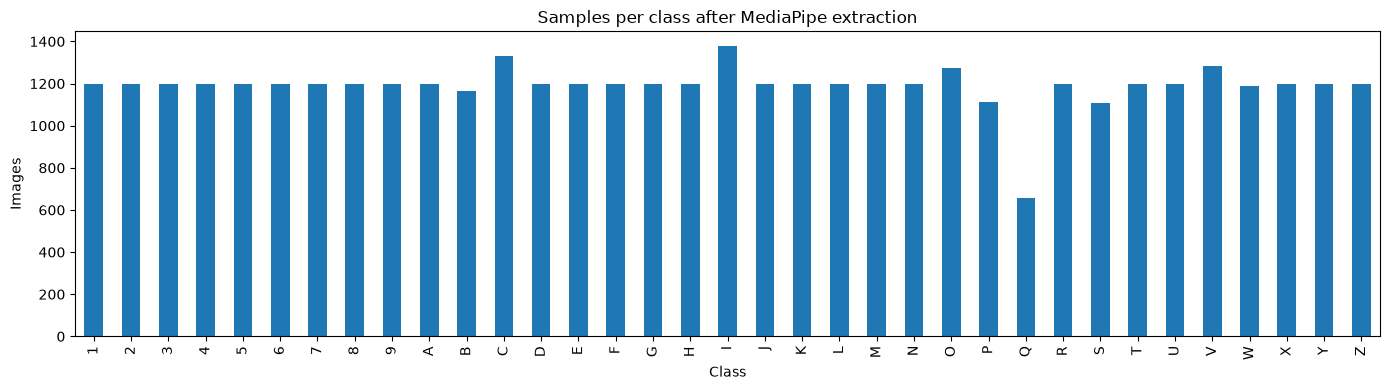

In [4]:
import matplotlib.pyplot as plt

print("Samples per class after landmark extraction:")
display(landmark_df["label"].value_counts().sort_index().to_frame("samples"))

landmark_df["label"].value_counts().sort_index().plot(kind="bar", figsize=(14, 4))
plt.title("Samples per class after MediaPipe extraction")
plt.xlabel("Class")
plt.ylabel("Images")
plt.tight_layout()
plt.show()


## 5. Train a baseline classifier

We use a stratified 80/20 split and a Random Forest as a baseline. Do not report the test score as definitive if the dataset contains repeated frames or multiple images from the same signer/session. For a stronger evaluation, use a signer/session-based split and test on new people recorded under different conditions.

Baseline test accuracy: 0.9996

              precision    recall  f1-score   support

           1       1.00      1.00      1.00       240
           2       1.00      1.00      1.00       240
           3       1.00      1.00      1.00       240
           4       1.00      1.00      1.00       240
           5       1.00      1.00      1.00       240
           6       1.00      1.00      1.00       240
           7       1.00      1.00      1.00       240
           8       1.00      1.00      1.00       240
           9       1.00      1.00      1.00       240
           A       1.00      1.00      1.00       240
           B       1.00      1.00      1.00       233
           C       1.00      1.00      1.00       266
           D       1.00      1.00      1.00       240
           E       1.00      1.00      1.00       240
           F       1.00      1.00      1.00       240
           G       1.00      1.00      1.00       240
           H       0.99      1.00      1.00      

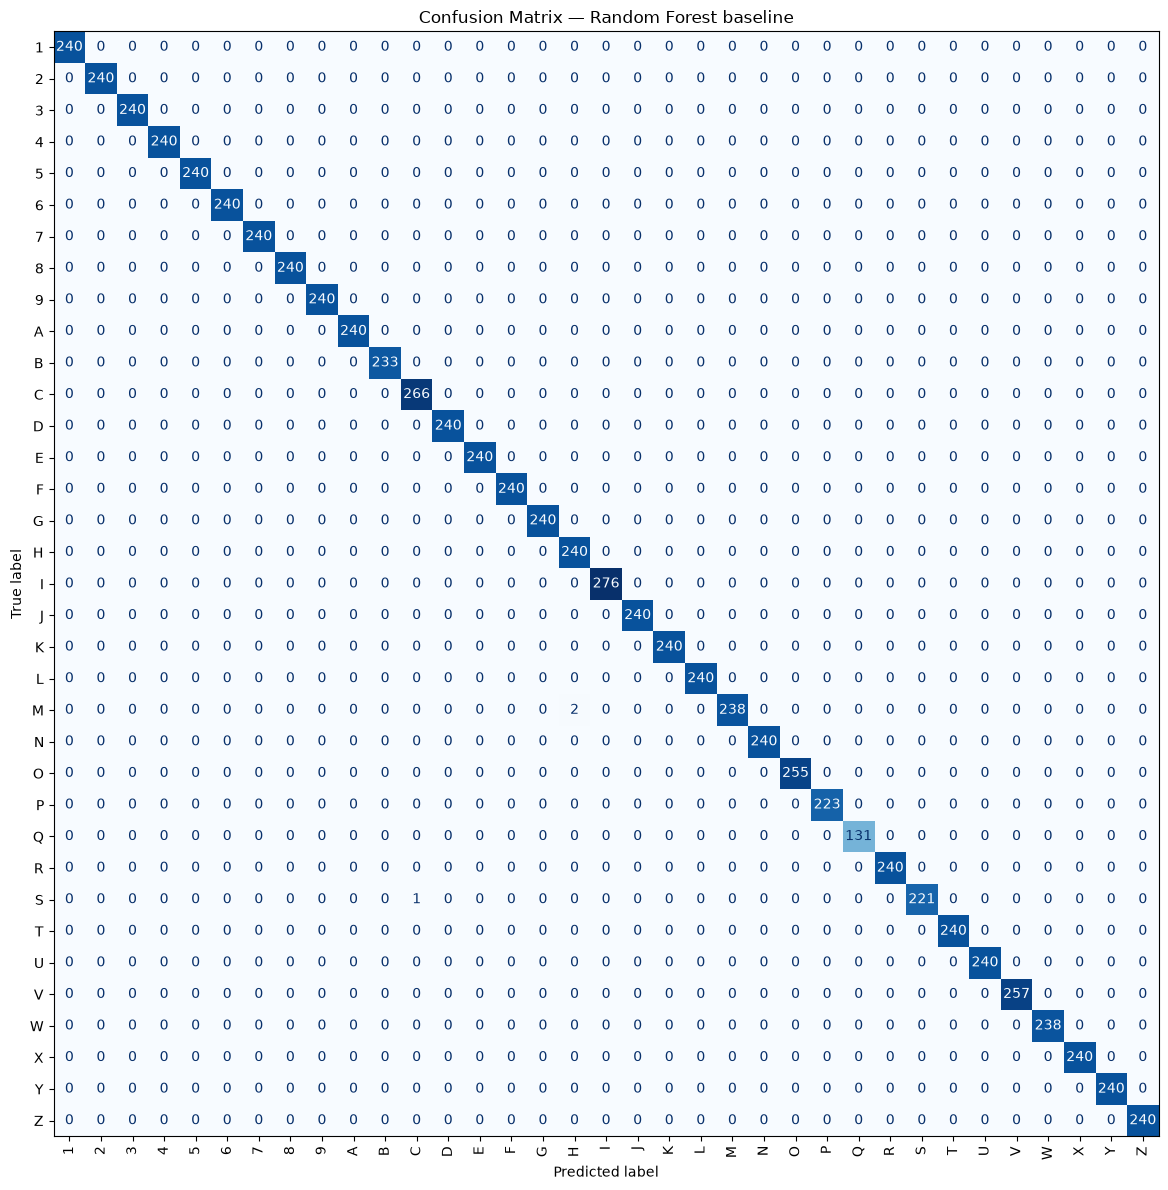

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import LabelEncoder
import joblib
import matplotlib.pyplot as plt

feature_cols = [c for c in landmark_df.columns if c.startswith("f")]
X = landmark_df[feature_cols].to_numpy(dtype=np.float32)
y_text = landmark_df["label"].astype(str).to_numpy()

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_text)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

model = RandomForestClassifier(
    n_estimators=400,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
    min_samples_leaf=1
)
model.fit(X_train, y_train)

pred = model.predict(X_test)
print(f"Baseline test accuracy: {accuracy_score(y_test, pred):.4f}")
print()
print(classification_report(
    y_test, pred,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))

fig, ax = plt.subplots(figsize=(14, 12))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred,
    labels=np.arange(len(label_encoder.classes_)),
    display_labels=label_encoder.classes_,
    xticks_rotation=90,
    cmap="Blues",
    ax=ax,
    colorbar=False
)
plt.title("Confusion Matrix — Random Forest baseline")
plt.tight_layout()
plt.show()


## 6. Save the trained model

Save the classifier, label encoder, and feature-column order together so the webcam script uses the exact same preprocessing layout.

In [5]:
MODEL_PATH = OUT_DIR / "isl_mediapipe_random_forest.joblib"
joblib.dump({
    "model": model,
    "label_encoder": label_encoder,
    "feature_cols": feature_cols,
    "class_names": list(label_encoder.classes_),
    "features_per_hand": 63,
    "number_of_hands": 2
}, MODEL_PATH)

print("Saved model bundle:", MODEL_PATH.resolve())


NameError: name 'OUT_DIR' is not defined

## 7. Test on a new image

Use an image not used during training. For a fair test, prefer a photo from a different capture session or signer.

In [4]:
def predict_image(image_path, model_bundle_path=MODEL_PATH):
    bundle = joblib.load(model_bundle_path)
    image = cv2.imread(str(image_path))
    if image is None:
        raise FileNotFoundError(f"Cannot read image: {image_path}")

    if max(image.shape[:2]) < 256:
        image = cv2.resize(image, (256, 256), interpolation=cv2.INTER_CUBIC)

    with mp_hands.Hands(
        static_image_mode=True,
        max_num_hands=2,
        model_complexity=1,
        min_detection_confidence=0.50
    ) as hands_model:
        feats, detected = extract_two_hand_features(image, hands_model)

    if not detected:
        return {"prediction": None, "message": "No hand detected. Try a clearer image."}

    X_one = pd.DataFrame([feats], columns=bundle["feature_cols"])
    probs = bundle["model"].predict_proba(X_one)[0]
    best = int(np.argmax(probs))
    return {
        "prediction": str(bundle["label_encoder"].inverse_transform([best])[0]),
        "confidence": float(probs[best])
    }

# Example: replace with an image path that you want to test.
# print(predict_image(r"C:\path\to\a_new_sign.jpg"))


## Practical notes

- **Do not confuse a landmark classifier with a full ISL translator.** This dataset supports static class recognition; it does not by itself teach sentence grammar or continuous signs.
- **Landmark detection can fail.** Keep track of missed images and inspect whether hands are too small, occluded, blurry, or cropped.
- **Two-hand ordering matters.** This notebook puts hands into Left/Right slots where MediaPipe handedness is available. Check the results with examples from your dataset.
- **Generalization matters more than one accuracy number.** Test with your own webcam, different lighting, different backgrounds, and people absent from training.
- If you want to recognize movement-based signs, collect labeled video sequences and train a temporal model (for example, LSTM or a temporal neural network) over landmark sequences.


In [2]:
from pathlib import Path

MODEL_PATH = Path(
    r"C:\AIML 5 D\Study material\Introduction to Deep Learning\mini\mini project\isl_mediapipe_output\isl_mediapipe_random_forest.joblib"
)

print("Model exists:", MODEL_PATH.exists())
print("Model path:", MODEL_PATH)

Model exists: True
Model path: C:\AIML 5 D\Study material\Introduction to Deep Learning\mini\mini project\isl_mediapipe_output\isl_mediapipe_random_forest.joblib


In [3]:
import joblib

bundle = joblib.load(MODEL_PATH)

print("Model loaded successfully!")
print("Available classes:", bundle["class_names"])

Model loaded successfully!
Available classes: ['1', '2', '3', '4', '5', '6', '7', '8', '9', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z']


In [6]:
import joblib
import cv2
import numpy as np
import pandas as pd
import mediapipe as mp

bundle = joblib.load(MODEL_PATH)

print("Model reloaded successfully")

Model reloaded successfully


In [17]:
import cv2
import numpy as np
import mediapipe as mp

mp_hands = mp.solutions.hands

def hand_to_features(hand_landmarks):
    pts = np.array(
        [[lm.x, lm.y, lm.z] for lm in hand_landmarks.landmark],
        dtype=np.float32
    )

    pts -= pts[0]
    scale = np.max(np.linalg.norm(pts[:, :2], axis=1))

    if scale > 1e-6:
        pts /= scale

    return pts.flatten()


def extract_two_hand_features(image_bgr, hands_model):
    rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    result = hands_model.process(rgb)

    slots = {
        "Left": np.zeros(63, dtype=np.float32),
        "Right": np.zeros(63, dtype=np.float32)
    }

    if not result.multi_hand_landmarks:
        return np.zeros(126, dtype=np.float32), False

    handedness = result.multi_handedness or []
    fallback = []

    for i, landmarks in enumerate(result.multi_hand_landmarks):
        label = None

        if i < len(handedness) and handedness[i].classification:
            label = handedness[i].classification[0].label

        features = hand_to_features(landmarks)

        if label in slots and np.all(slots[label] == 0):
            slots[label] = features
        else:
            fallback.append(features)

    for label in ("Left", "Right"):
        if np.all(slots[label] == 0) and fallback:
            slots[label] = fallback.pop(0)

    return np.concatenate([slots["Left"], slots["Right"]]), True

In [18]:
print(hand_to_features)
print(extract_two_hand_features)

<function hand_to_features at 0x0000026DD3FBC040>
<function extract_two_hand_features at 0x0000026DD3FBD260>


In [19]:
print("Hand feature function:", callable(hand_to_features))
print("Two-hand feature function:", callable(extract_two_hand_features))
print("Saved model exists:", MODEL_PATH.exists())

Hand feature function: True
Two-hand feature function: True
Saved model exists: True


In [20]:
import joblib

bundle = joblib.load(MODEL_PATH)

print("Model loaded:", bundle["model"] is not None)
print("Number of classes:", len(bundle["class_names"]))
print("Classes:", bundle["class_names"])

Model loaded: True
Number of classes: 35
Classes: ['1', '2', '3', '4', '5', '6', '7', '8', '9', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z']


In [21]:
import cv2
import numpy as np
import pandas as pd
import mediapipe as mp

print("Ready to test ISL sign images!")

Ready to test ISL sign images!


In [23]:
image_path = r"C:\AIML 5 D\Study material\Introduction to Deep Learning\mini\mini project\test1.jpg"

result = predict_image(image_path)

print("Prediction:", result)

Prediction: {'prediction': 'T', 'confidence': 0.825}


C:\Users\Admin\isl_env\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(


In [4]:
import cv2
import numpy as np
import mediapipe as mp
import joblib

# Load your trained model
bundle = joblib.load(MODEL_PATH)
model = bundle["model"]
label_encoder = bundle["label_encoder"]

mp_hands = mp.solutions.hands
mp_draw = mp.solutions.drawing_utils

cap = cv2.VideoCapture(0)

if not cap.isOpened():
    print("Camera could not be opened. Close other camera apps and try again.")
else:
    with mp_hands.Hands(
        static_image_mode=False,
        max_num_hands=2,
        model_complexity=1,
        min_detection_confidence=0.5,
        min_tracking_confidence=0.5
    ) as hands:

        while True:
            success, frame = cap.read()

            if not success:
                print("Could not read from camera.")
                break

            frame = cv2.flip(frame, 1)
            features, detected = extract_two_hand_features(frame, hands)

            if detected:
                X_one = np.asarray([features], dtype=np.float32)
                probs = model.predict_proba(X_one)[0]
                best = int(np.argmax(probs))
                prediction = label_encoder.inverse_transform([best])[0]
                confidence = float(probs[best])

                cv2.putText(
                    frame,
                    f"{prediction} ({confidence:.1%})",
                    (30, 50),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    1.2,
                    (0, 255, 0),
                    3
                )
                mp_draw.draw_landmarks(
                    frame,
                    hands.process(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)).multi_hand_landmarks[0]
                    if False else None,
                    mp_hands.HAND_CONNECTIONS
                )
            else:
                cv2.putText(
                    frame, "No hand detected", (30, 50),
                    cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 255), 2
                )

            cv2.imshow("ISL Live Sign Recognition - Press Q to quit", frame)

            if cv2.waitKey(1) & 0xFF == ord("q"):
                break

    cap.release()
    cv2.destroyAllWindows()

SyntaxError: invalid syntax (3047570366.py, line 63)

In [41]:
cap = cv2.VideoCapture("http://192.168.29.117:4747/video")

In [42]:
import cv2
for i in range(5):
    cap = cv2.VideoCapture(i)
    print(i, cap.isOpened())
    cap.release()

0 True
1 True
2 False
3 False
4 False


In [43]:
import cv2

for i in [0, 1]:
    cap = cv2.VideoCapture(i)
    ok, frame = cap.read()
    print(i, "opened:", cap.isOpened(), "frame read:", ok)
    if ok:
        cv2.imshow(f"Camera {i} - press any key", frame)
        cv2.waitKey(0)
        cv2.destroyAllWindows()
    cap.release()

0 opened: True frame read: True
1 opened: True frame read: True


In [2]:
cap = cv2.VideoCapture(CAMERA_SOURCE)

In [3]:
cap = cv2.VideoCapture(CAMERA_SOURCE, cv2.CAP_MSMF)

In [4]:

from pathlib import Path
import joblib
import numpy as np
import cv2
import mediapipe as mp

MODEL_PATH = Path(
    r"C:\AIML 5 D\Study material\Introduction to Deep Learning\mini\mini project\isl_mediapipe_output\isl_mediapipe_random_forest.joblib"
)

print("Model file exists:", MODEL_PATH.exists())

if MODEL_PATH.exists():
    bundle = joblib.load(MODEL_PATH)
    model = bundle["model"]
    label_encoder = bundle["label_encoder"]
    print("Model loaded successfully!")
    print("Number of classes:", len(bundle["class_names"]))
else:
    print("Check the model path above.")


Model file exists: True
Model loaded successfully!
Number of classes: 35


In [5]:
print("Model ready:", model is not None)
print("Feature extraction ready:", callable(extract_two_hand_features))

Model ready: True
Feature extraction ready: True


In [6]:
print("Model ready:", model is not None)
print("Feature function ready:", callable(hand_to_features))
print("Two-hand function ready:", callable(extract_two_hand_features))

Model ready: True
Feature function ready: True
Two-hand function ready: True


In [8]:

import cv2
import numpy as np
import mediapipe as mp

# 0 = built-in laptop webcam
cap = cv2.VideoCapture(0, cv2.CAP_DSHOW)

if not cap.isOpened():
    print("Could not open laptop camera. Close the Windows Camera app and try again.")
else:
    print("Laptop camera connected! Press Q in the camera window to quit.")

    with mp.solutions.hands.Hands(
        static_image_mode=False,
        max_num_hands=2,
        model_complexity=1,
        min_detection_confidence=0.5,
        min_tracking_confidence=0.5
    ) as hands:

        while True:
            success, frame = cap.read()

            if not success:
                print("Could not read from laptop camera.")
                break

            frame = cv2.flip(frame, 1)

            # Extract hand features using your existing function
            features, detected = extract_two_hand_features(frame, hands)

            if detected:
                X_one = np.asarray([features], dtype=np.float32)
                probs = model.predict_proba(X_one)[0]

                best = int(np.argmax(probs))
                prediction = label_encoder.inverse_transform([best])[0]
                confidence = float(probs[best])

                text = f"Sign: {prediction} ({confidence:.1%})"
                color = (0, 255, 0)
            else:
                text = "No hand detected"
                color = (0, 0, 255)

            cv2.putText(
                frame, text, (20, 50),
                cv2.FONT_HERSHEY_SIMPLEX, 1,
                color, 2
            )

            cv2.imshow("ISL Recognition - Laptop Webcam", frame)

            if cv2.waitKey(1) & 0xFF == ord("q"):
                break

    cap.release()
    cv2.destroyAllWindows()


Laptop camera connected! Press Q in the camera window to quit.
